## RISK MANAGEMENT
MODULE 8 | GROUP WORK PROJECT 3

---


# **INTERPRETATION OF RESULTS AND IMPROVEMENT OF THE MODEL**

Group 18580. Yetgang Kengne Blairio Giacomoni, Oranan Ariyarit, Samuel Udochukwu Iroanya.

|  |  |
|:---|:---|
|**Input** | the sterilised monthly panel delivered in GWP1, 439 months on 29 columns |
|**Run time** | about three minutes end to end |
|**Dependencies** | numpy, pandas, matplotlib, networkx, pgmpy 1.1.2 |

---


This notebook answers the seven steps of the assignment in order. Each step has a
short statement of what it asks, the code that answers it, and the answer in words
underneath the output. No cell re-downloads data. The GWP2 package is imported rather
than copied, so the two cannot drift apart.

Run it from the root of the repository, so that `src/` and `data_clean/` sit
next to it.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import gwp2_core as g
import gwp3_core as c
import pipeline_gwp3 as p3
from pipeline_gwp2 import model_nodes

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("hidden Markov backend:", g.HMMS_BACKEND)
print("pandas", pd.__version__, "| numpy", np.__version__)

hidden Markov backend: hmms_compat (pure NumPy, numerically identical)
pandas 3.0.5 | numpy 2.5.3


## **1. Steps 1 and 2. The three datasets and the allocation of the data**

Step 1 asks each member to define the purpose of one window. Step 2 asks the group to
compare the validation and the test window and to show how the data are allocated. The
written answers are in sections 2 and 3 of the report; the allocation itself is below.

In [2]:
monthly = g.load_monthly()
panel = monthly[model_nodes()]
train_idx, valid_idx, test_idx = g.split_index(panel.index)

allocation = pd.DataFrame({
    "window": ["Training", "Validation", "Test"],
    "months": [len(train_idx), len(valid_idx), len(test_idx)],
    "share": [round(len(x) / len(panel), 3) for x in (train_idx, valid_idx, test_idx)],
    "from": [x[0].date() for x in (train_idx, valid_idx, test_idx)],
    "to": [x[-1].date() for x in (train_idx, valid_idx, test_idx)],
    "may fit parameters": ["yes", "no", "no"],
    "may choose between models": ["no", "yes", "no"],
    "may be reported out of sample": ["no", "no", "yes"],
})
print(f"panel: {panel.shape[0]} months x {panel.shape[1]} variables")
print(f"causal decoding discards a {c.WARMUP}-month warm-up, "
      f"leaving {len(valid_idx) - 3} validation and {len(test_idx) - 2} test months")
allocation

panel: 439 months x 17 variables
causal decoding discards a 24-month warm-up, leaving 41 validation and 42 test months


,window,months,share,from,to,may fit parameters,may choose between models,may be reported out of sample
0,Training,351,0.8,1990-01-01,2019-03-01,yes,no,no
1,Validation,44,0.1,2019-04-01,2022-11-01,no,yes,no
2,Test,44,0.1,2022-12-01,2026-07-01,no,no,yes


**Answer.** The panel holds 439 months on 17 model variables, split 351 / 44 / 44 in
calendar order, which is the 80:10:10 ratio of the dissertation (Alvi 46). The training
window is the only one any estimator reads, including the hidden Markov models and the
rule that maps raw states to bear, stagnant and bull. The validation window chooses the
structure score, the in-degree cap and the width of the dead band. The test window is
read once. Causal decoding warms up for 24 months, so figures under that rule are scored
on 41 validation and 42 test months.

## **2. Steps 3 and 4. Re-reading section 4.3 and re-running the search**

Step 3 asks each person to re-read section 4.3 of the dissertation. Step 4 asks the group
to re-run the Hill Climb search and to confirm whether the published results replicate.

The whole analysis runs from one call. It takes about three minutes, most of it in the
causal decoding, which re-runs the Viterbi recursion on an expanding window for every
month of every variable.

In [3]:
res, band_tbl, sweep, scores, dur, bt, keep = p3.run(verbose=True)

  0%|          | 0/44 [00:00<?, ?it/s]

 36%|███▋      | 16/44 [00:00<00:00, 142.31it/s]

 73%|███████▎  | 32/44 [00:00<00:00, 144.27it/s]

100%|██████████| 44/44 [00:00<00:00, 131.08it/s]

  0%|          | 0/44 [00:00<?, ?it/s]

 32%|███▏      | 14/44 [00:00<00:00, 137.18it/s]

... (134 outputs left out)

 95%|█████████▌| 40/42 [00:00<00:00, 117.49it/s]

100%|██████████| 42/42 [00:00<00:00, 116.83it/s]

[E4] q=0.40 acc valid 1.000 test 1.000 | balanced valid nan test nan | largest class 1.000


[final] score=k2 q=0.1 valid 0.976 test 0.905
figures: G8_data_allocation.png, G9_replication.png, G10_indegree.png, G11_score_selection.png, G12_dead_band.png, G13_episode_duration.png, G14_backtest.png, G15_final_network.png
runtime 173.6 s


,quantity,Alvi (2018),this replication
0,validation accuracy,0.3214,0.7045
1,test accuracy,0.5714,0.7273
2,months scored,28 and 28,44 and 44
3,edges in the learnt graph,not published,18
4,Markov blanket of the target,not published,"CPIENG, INDPRO, PPI_OILGAS, WTI_M"
5,structure score,"BIC in the text, K2 in the code",K2


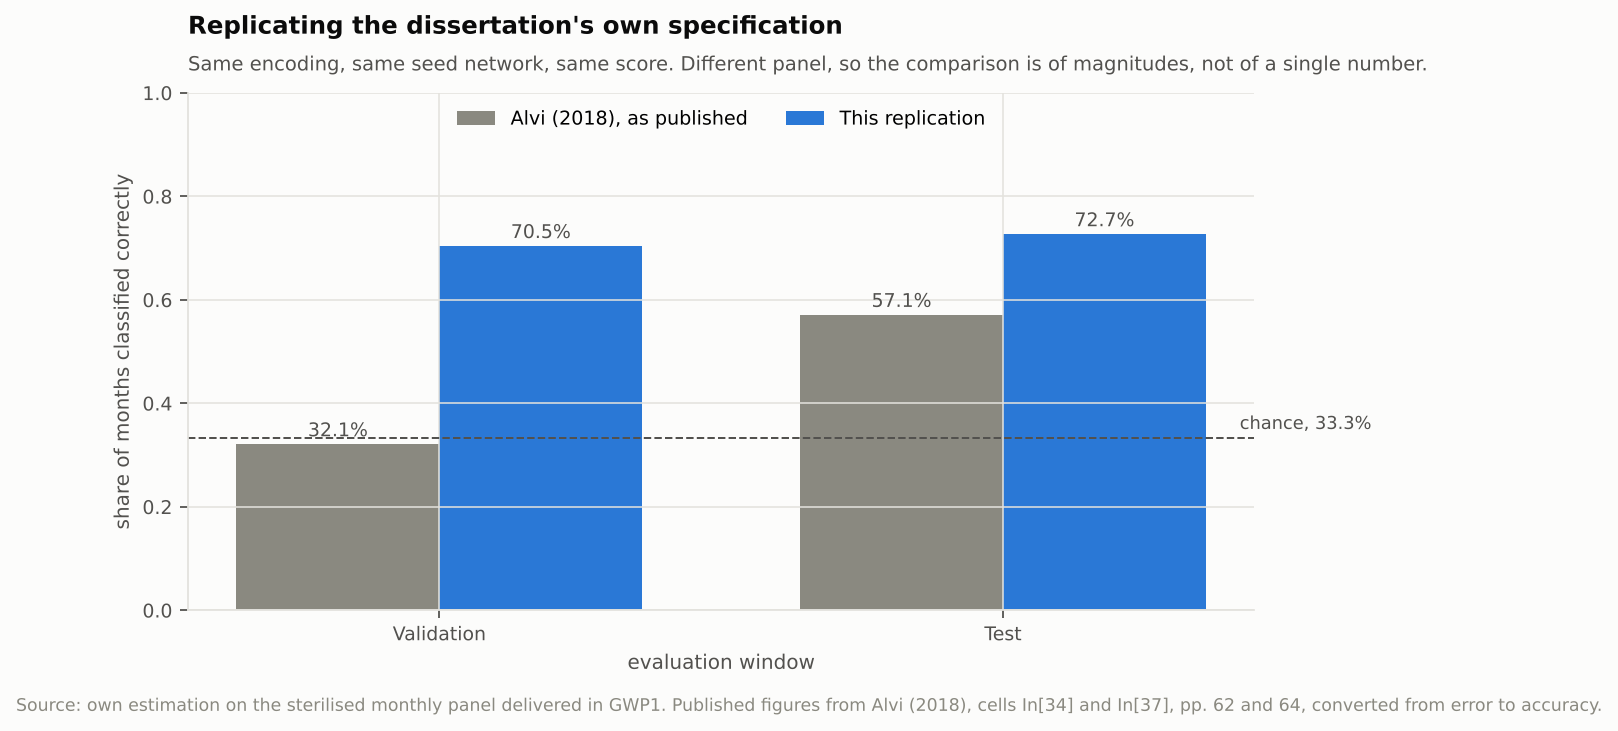

In [4]:
rep = res["replication"]
replication = pd.DataFrame({
    "quantity": ["validation accuracy", "test accuracy", "months scored",
                 "edges in the learnt graph", "Markov blanket of the target",
                 "structure score"],
    "Alvi (2018)": [rep["alvi"]["valid_accuracy"], rep["alvi"]["test_accuracy"],
                    "28 and 28", "not published", "not published",
                    "BIC in the text, K2 in the code"],
    "this replication": [rep["ours"]["valid"]["network_accuracy"],
                         rep["ours"]["test"]["network_accuracy"], "44 and 44",
                         rep["ours"]["n_edges"], ", ".join(rep["ours"]["blanket"]), "K2"],
})
display(replication)
display(Image("figures/G9_replication.png"))

**Answer to step 4b.** The published results cannot be replicated in detail, and the
obstacle is in the dissertation rather than in our run. No edge list, no conditional
probability table and no readable network figure is published, so there is no structural
artefact to compare against. The network figure in the PDF is empty.

What replicates is the procedure and the order of magnitude. Our run reaches 70.5 per
cent on validation and 72.7 per cent on test, against his 32.1 and 57.1 per cent. His
validation figure sits below the one-in-three chance level for a three-class problem,
which points to something broken in his validation run rather than to a weak model.

One further result: seeding the search with Alvi's edges and with the GWP2 edges gives
the same graph, the same Markov blanket and the same accuracy. The expert seed does not
survive contact with the data.

In [5]:
# What an uncapped search does, measured rather than asserted.
pd.Series(res["uncapped_probe"])

status         completed
max_parents           17
cpt_cells      559607460
n_edges               55
seconds              4.1
dtype: object

**Why the in-degree is capped.** The uncapped search finishes in a few seconds and
returns a graph that asks for more than five hundred million probability cells from 351
months of data, with one node carrying seventeen parents. GWP2 reported this as an
anecdote; here it is a measurement.

## **3. Step 5a. The accuracy of the forecast**

Accuracy alone is reported by the dissertation. Two further measures are reported here.
Balanced accuracy is the mean recall across the regimes that occur, so a model that
always names the dominant regime scores at the floor. Macro F1 is the unweighted mean of
the per-class F1 scores.

In [6]:
b = res["baseline"]
rows = []
for tag, label in [("smoothed", "Smoothed"), ("causal", "Causal")]:
    for win in ("valid", "test"):
        r = b[tag][win]
        rows.append({"decoding": label, "window": win, "n": r["n"],
                     "accuracy": r["network_accuracy"],
                     "balanced accuracy": r["balanced_accuracy"],
                     "macro F1": r["macro_f1"],
                     "largest class": r["largest_class_share"],
                     "persistence": r["persistence_accuracy"],
                     "majority": r["majority_accuracy"]})
pd.DataFrame(rows)

,decoding,window,n,accuracy,balanced accuracy,macro F1,largest class,persistence,majority
0,Smoothed,valid,44,0.7045,0.6902,0.6803,0.3864,0.3636,0.3864
1,Smoothed,test,44,0.7273,0.6799,0.6895,0.4773,0.3864,0.4773
2,Causal,valid,41,0.5854,0.3333,0.2462,0.5854,0.5122,0.5854
3,Causal,test,42,0.4524,0.3333,0.2077,0.4524,0.5238,0.4524


**Answer to step 5a.** Under smoothed decoding the model reaches 72.7 per cent on the
test window, with balanced accuracy of 68.0 per cent, so the figure is not an artefact of
class imbalance. That decoding is not available at the forecast date.

Under causal decoding the model reaches 45.2 per cent, which is exactly the majority
class, with balanced accuracy of 33.3 per cent and macro F1 of 20.8 per cent. Two of the
three regimes are never predicted. The causal model does not forecast weakly; it does not
forecast.

### 3.1 The comparisons the dissertation describes and never publishes

Alvi states that the validation window selects among BDeu, K2 and BIC (Alvi 46). The
comparison follows, together with the in-degree sweep that justifies the cap.

,score,label,n_edges,blanket,valid_accuracy,valid_balanced,test_accuracy,test_balanced
0,k2,K2,16,WTI_M,0.5854,0.3333,0.4524,0.3333
1,bic-d,BIC,8,WTI_M,0.5854,0.3333,0.4524,0.3333
2,bdeu,BDeu,16,WTI_M,0.5854,0.3333,0.4524,0.3333


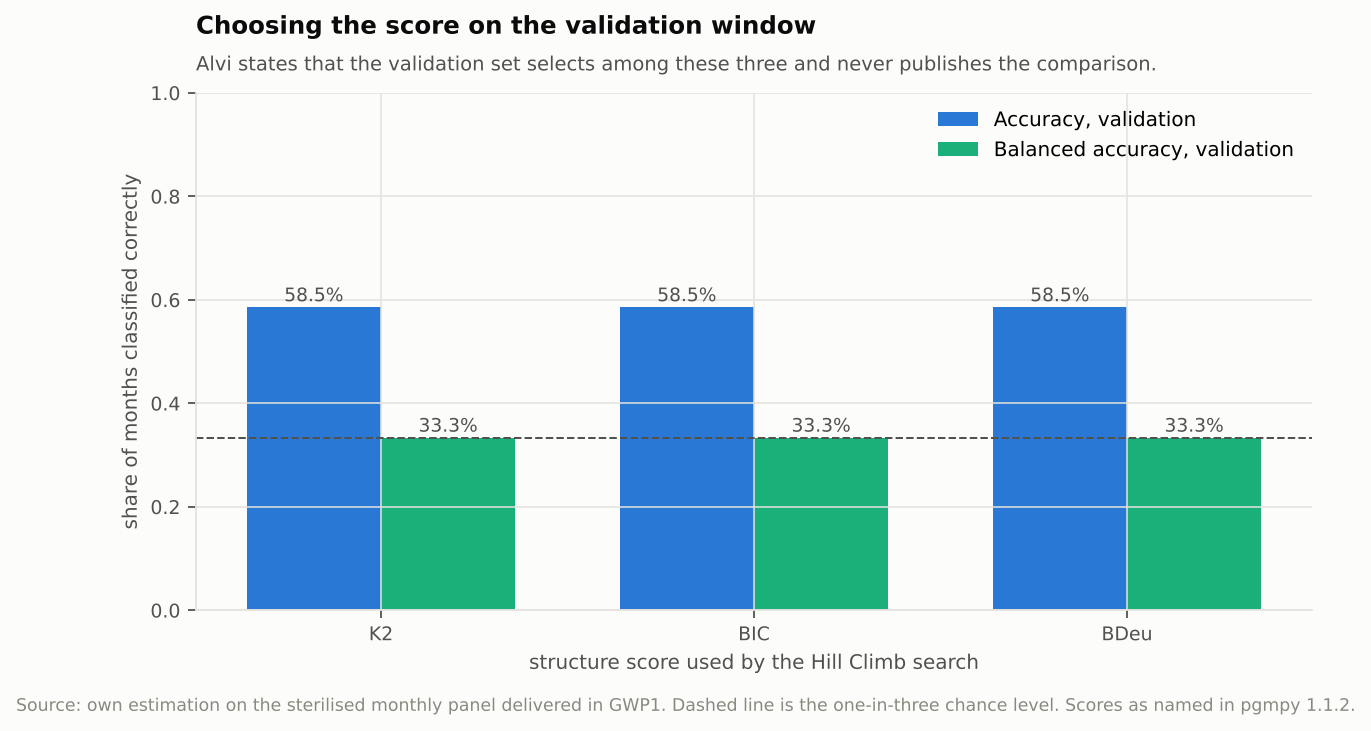

,max_indegree,n_edges,cpt_cells,obs_per_cell,valid_accuracy,valid_balanced,test_accuracy,test_balanced,blanket
0,1,12,126,2.7857,0.5854,0.3333,0.4524,0.3333,WTI_M
1,2,14,174,2.0172,0.5854,0.3333,0.4524,0.3333,WTI_M
2,3,16,282,1.2447,0.5854,0.3333,0.4524,0.3333,WTI_M
3,4,20,678,0.5177,0.5854,0.3333,0.4524,0.3333,WTI_M
4,5,21,1164,0.3015,0.5854,0.3333,0.4524,0.3333,WTI_M


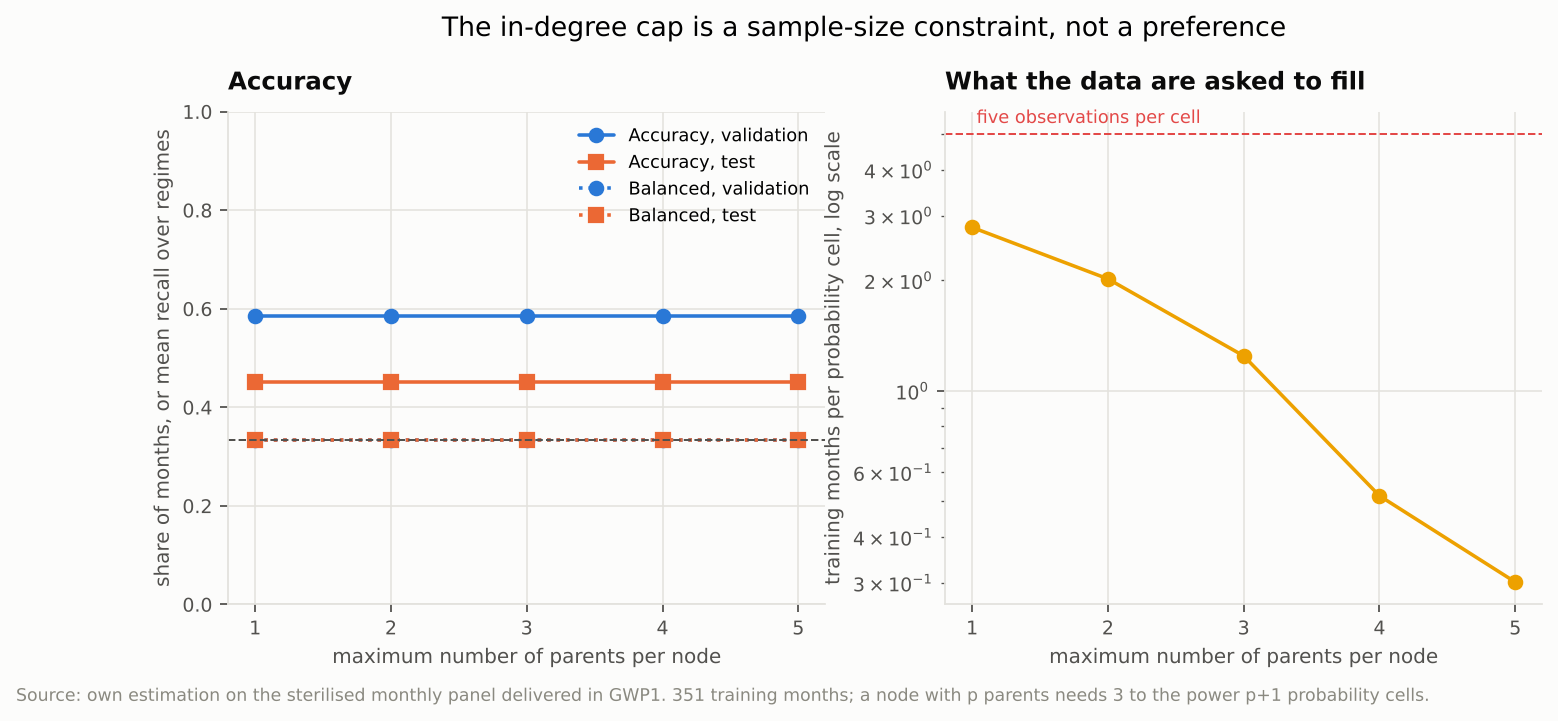

In [7]:
display(scores)
display(Image("figures/G11_score_selection.png"))
display(sweep)
display(Image("figures/G10_indegree.png"))

**What this shows.** The three scores disagree about the graph and agree about the
forecast: BIC returns half as many edges as K2 and BDeu, and all three leave the Markov
blanket of the target containing the current price and nothing else. The in-degree sweep
is flat to four decimal places from one parent to five, while the number of probability
cells grows almost tenfold. Under causal decoding, neither hyperparameter is a modelling
decision.

## **4. Step 5b. A graphical way to display the results, and the improvement**

The first improvement named in the GWP2 bridge was a three-symbol alphabet with a dead
band, so that the encoding can record that nothing happened rather than forcing every
month to be a rise or a fall.

,q,band_wti,n_symbols,n_edges,valid_accuracy,valid_balanced,valid_largest_class,valid_degenerate,test_degenerate,test_accuracy,test_balanced,test_macro_f1,test_largest_class,test_classes_observed,persistence_test,majority_test,share_bear,share_stagnant,share_bull
0,0.0,0.0000,2,16,0.5854,0.3333,0.5854,False,False,0.4524,0.3333,0.2077,0.4524,3,0.5238,0.4524,0.395,0.212,0.393
1,0.1,0.3445,3,22,0.9756,0.6667,0.9512,False,False,0.9048,0.6574,0.6486,0.8571,3,0.7857,0.8571,0.094,0.781,0.126
2,0.2,0.6382,3,30,1.0000,NaN,1.0000,True,True,1.0000,NaN,NaN,1.0000,1,1.0000,1.0000,0.144,0.813,0.043
3,0.3,1.0340,3,34,1.0000,NaN,1.0000,True,True,1.0000,NaN,NaN,1.0000,1,1.0000,1.0000,0.062,0.064,0.874
4,0.4,1.3120,3,30,1.0000,NaN,1.0000,True,True,1.0000,NaN,NaN,1.0000,1,1.0000,1.0000,0.135,0.137,0.728


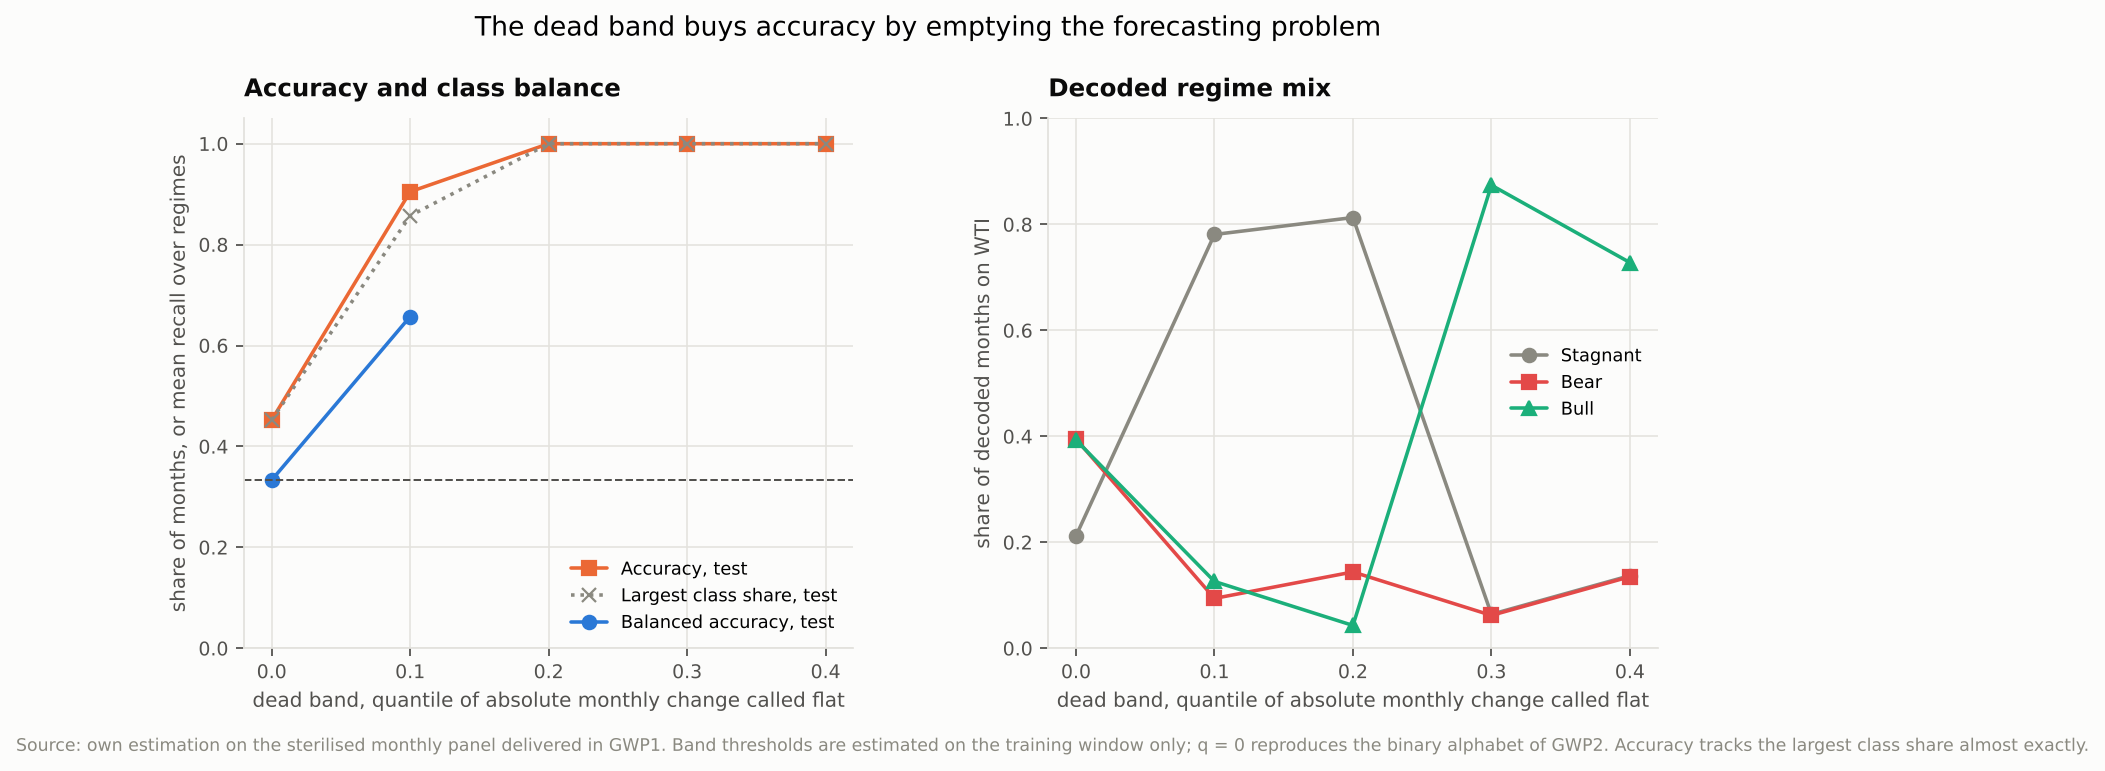

In [8]:
display(band_tbl)
display(Image("figures/G12_dead_band.png"))

**The trap, and the finding.** Read the accuracy column alone and the dead band looks
like the best result in the three projects, rising to 100 per cent. Read the last columns
and it dissolves: from a band of 0.20 the test window contains a single regime, the target
is a constant, every baseline also scores 100 per cent, and balanced accuracy is undefined.

Accuracy tracks the largest class share almost exactly across the sweep. That is the
signature of a metric measuring class imbalance rather than skill, and it is the reason
the selection below is made on balanced accuracy with degenerate windows excluded.

selected: score=k2, max in-degree=3, dead band q=0.1


,validation,test
n,41,42
network_accuracy,0.9756,0.9048
persistence_accuracy,0.9268,0.7857
majority_accuracy,0.9512,0.8571
chance,0.3333,0.3333
balanced_accuracy,0.6667,0.6574
macro_f1,0.6624,0.6486
classes_observed,3,3
largest_class_share,0.9512,0.8571
degenerate_window,False,False


,binary,banded
bear,1.86,1.32
stagnant,1.00,13.68
bull,2.12,1.00


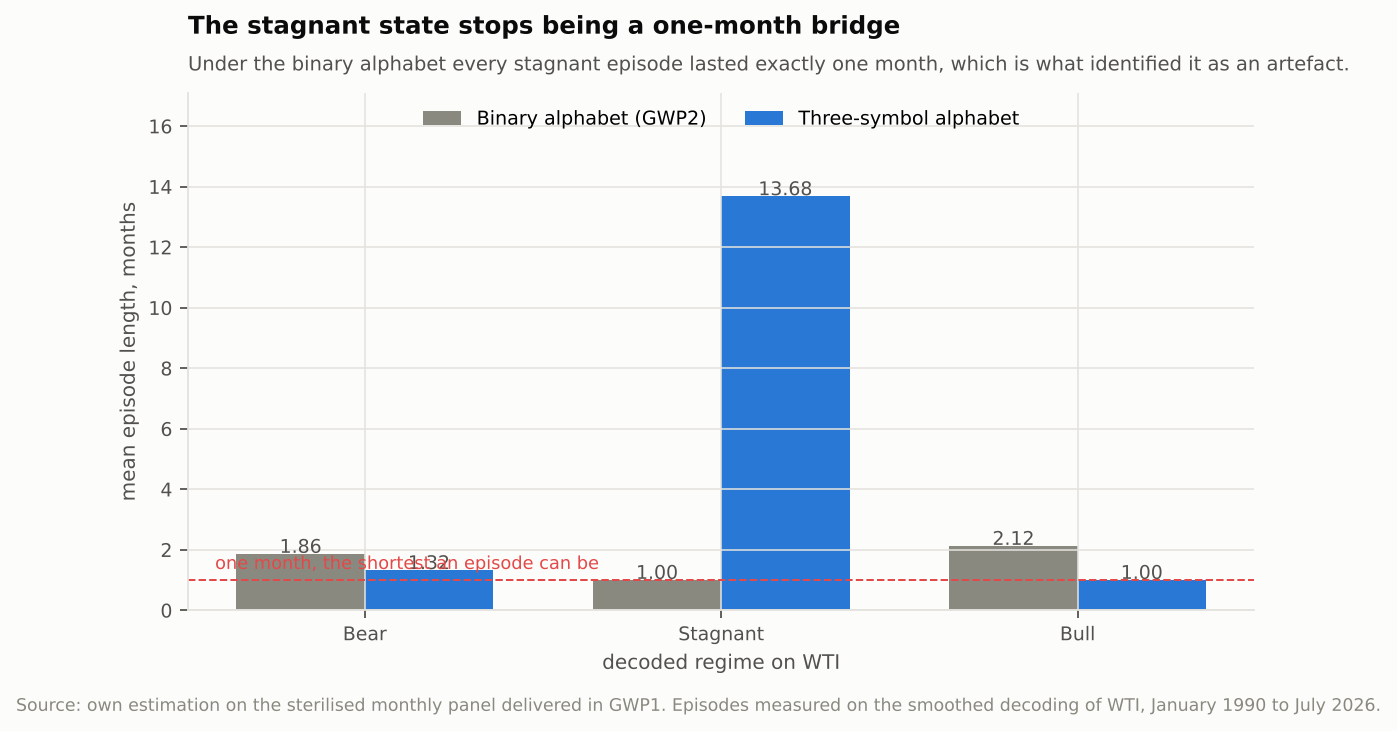

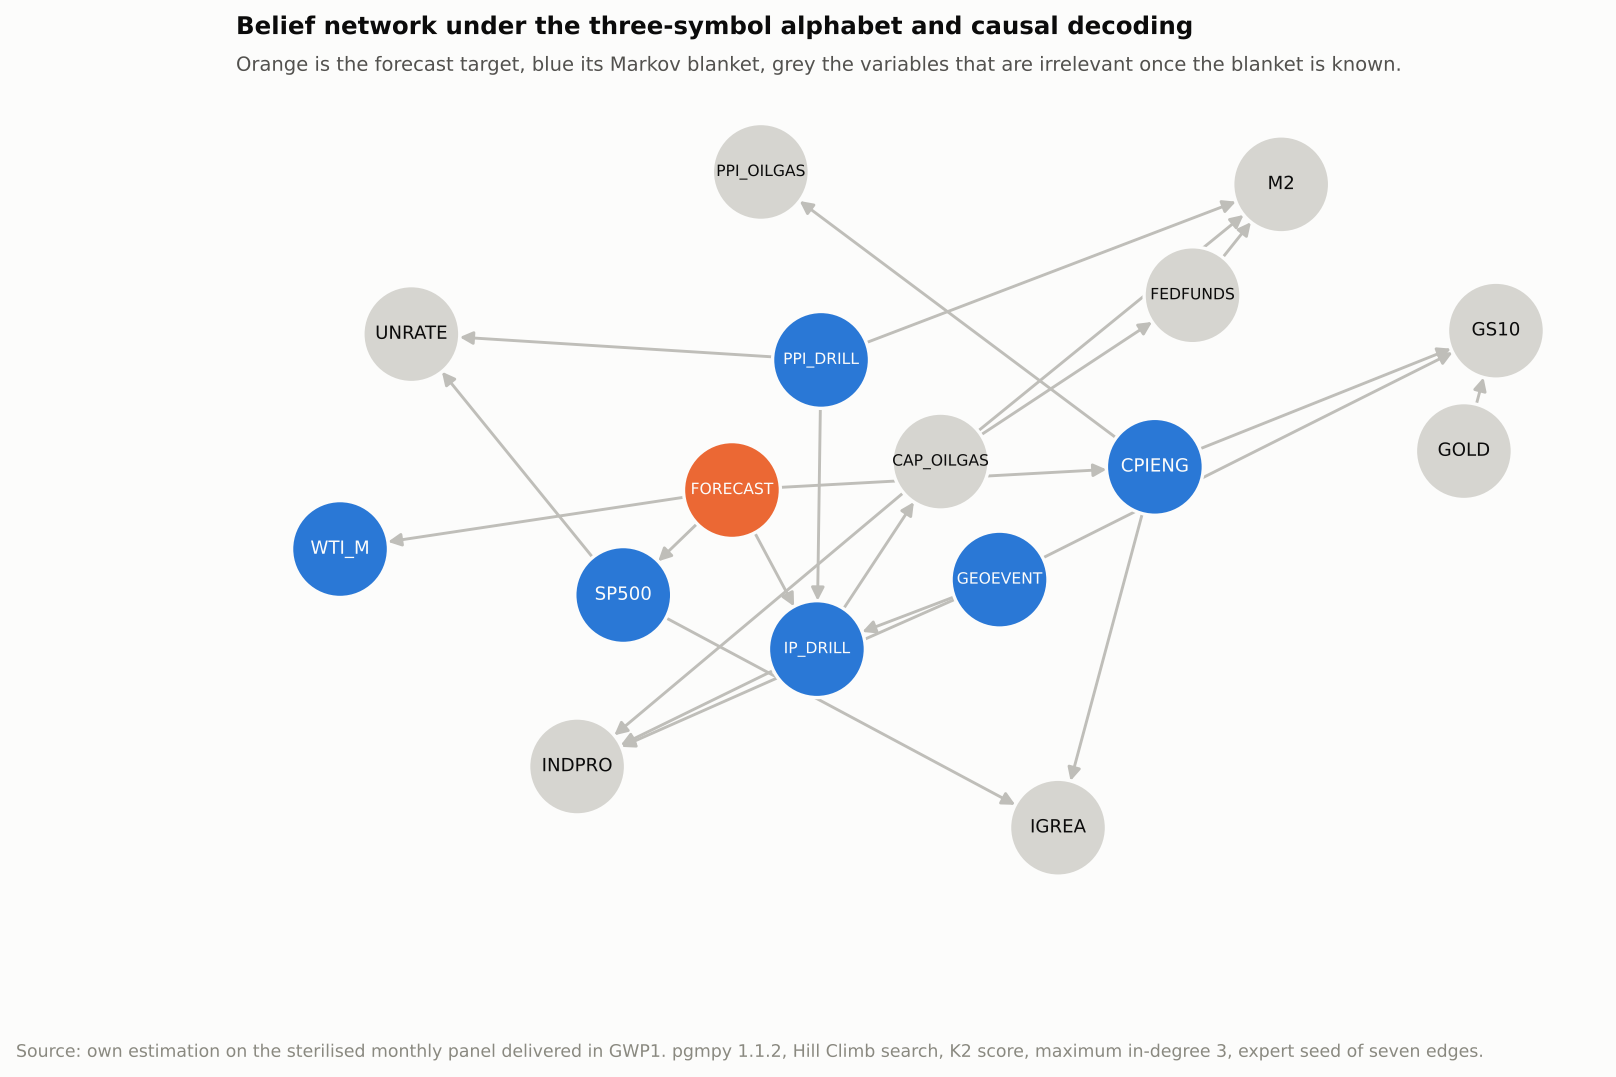

In [9]:
f = res["final"]
print("selected:", f"score={f['score']}, max in-degree={f['max_indegree']}, "
      f"dead band q={f['dead_band_q']}")
display(pd.DataFrame({"validation": f["valid"], "test": f["test"]}))
display(pd.DataFrame(res["episode_lengths"]))
display(Image("figures/G13_episode_duration.png"))
display(Image("figures/G15_final_network.png"))

**Answer.** Measured properly the improvement is real and modest. Balanced accuracy on
the test window rises from 33.3 per cent, the floor, to 65.7 per cent, and macro F1 from
20.8 to 64.9 per cent. The model predicts all three regimes instead of one. Raw accuracy
of 90.5 per cent clears the majority class at 85.7 and persistence at 78.6, so the gain
survives its baselines by about five percentage points rather than the forty-five the
headline suggests.

The structural change is larger than the accuracy change. The Markov blanket of the
target grows from one variable to six, and the constructed geopolitical event flag,
ignored by every model in GWP2, is one of them.

The old artefact is gone and a new one has appeared. Mean stagnant duration rises from
exactly one month to 13.68, which is what a quiet market should look like, while bull
episodes collapse to exactly one month. A volatility-scaled band is the next
experiment.

## **5. Step 6. Assessing the eight proposed contributions**

The dissertation lists its contributions on pages 66 and 67, numbering them First to
Lastly and using Secondly twice. Merging the duplicated claim leaves eight.

In [10]:
contrib = pd.DataFrame(c.CONTRIBUTIONS, columns=["id", "claim", "where it is made"])
verdicts = {
    "C1": "not delivered: no covariance matrix, equilibrium returns or view matrix exist",
    "C2": "delivered as a mechanism, unproven as a novelty: no supporting survey",
    "C3": "prototype only: the published loop returns no profit and loss series",
    "C4": "contradicted by cell In[29], which seeds six expert edges",
    "C5": "unfalsifiable, and the stack no longer runs on current libraries",
    "C6": "not delivered: no geopolitical variable enters the data",
    "C7": "not demonstrated: no intervention or policy counterfactual is performed",
    "C8": "not measured: no benchmark and no risk adjustment are computed",
}
contrib["verdict"] = contrib["id"].map(verdicts)
contrib

,id,claim,where it is made,verdict
0,C1,Bayesian views replace EGARCH-M views in Black...,"p. 66, citing Beach and Orlov, reference [15]","not delivered: no covariance matrix, equilibri..."
1,C2,Discretising time series with hidden Markov mo...,"p. 66, stated twice, as Secondly and as Fourthly","delivered as a mechanism, unproven as a novelt..."
2,C3,"A working trading mechanism, directly deployab...","p. 66, and the trading loop of cell In[39], p. 64",prototype only: the published loop returns no ...
3,C4,An almost autonomous system requiring no prior...,"p. 66, against the expert seed of cell In[29],...","contradicted by cell In[29], which seeds six e..."
4,C5,The abstraction offered by the Python modules ...,"pp. 66 to 67, and section 2.2, p. 28","unfalsifiable, and the stack no longer runs on..."
5,C6,"A systematic, event-driven global macro strate...","p. 67, and section 3.1, p. 34",not delivered: no geopolitical variable enters...
6,C7,Better models of energy markets for policy makers,"p. 67, and the Contributions to Science prefac...",not demonstrated: no intervention or policy co...
7,C8,An amalgamation of multidisciplinary research ...,p. 67,not measured: no benchmark and no risk adjustm...


**Answer to step 6c and 6d.** Three of the eight are delivered in some form, four are
proposed and not delivered, and one cannot be tested. The core of the dissertation, a
regime detector feeding a structure learner, works. The claims built around that core, in
the language of asset allocation, autonomy, policy and alpha, are not supported by its own
pages. The full evidence for each verdict, with page citations, is in section 7 of the
report.

Two of these matter most. The autonomy claim matters because the motivation for the whole
method is that expert judgement is slow and error-prone, so an expert seed in the code
undercuts the argument. The alpha claim matters because it is the one a desk would act on,
and it is the one with no number attached. The next section attaches one.

## **6. Step 7. What the forecast is worth as a position**

The forecast regime becomes a position in one barrel: long on bull, short on bear, flat on
stagnant, which is the signal convention of the dissertation (Alvi 64). The position taken
at the close of a month earns the log return of the following month.

,strategy,cumulative_return,annualised_return,annualised_vol,return_over_vol,max_drawdown,months_long,months_short,months_flat
0,Belief network signal,0.1206,0.0333,0.0630,0.529,-0.0516,3,1,37
1,Buy and hold,0.0856,0.0240,0.2932,0.082,-0.3518,41,0,0


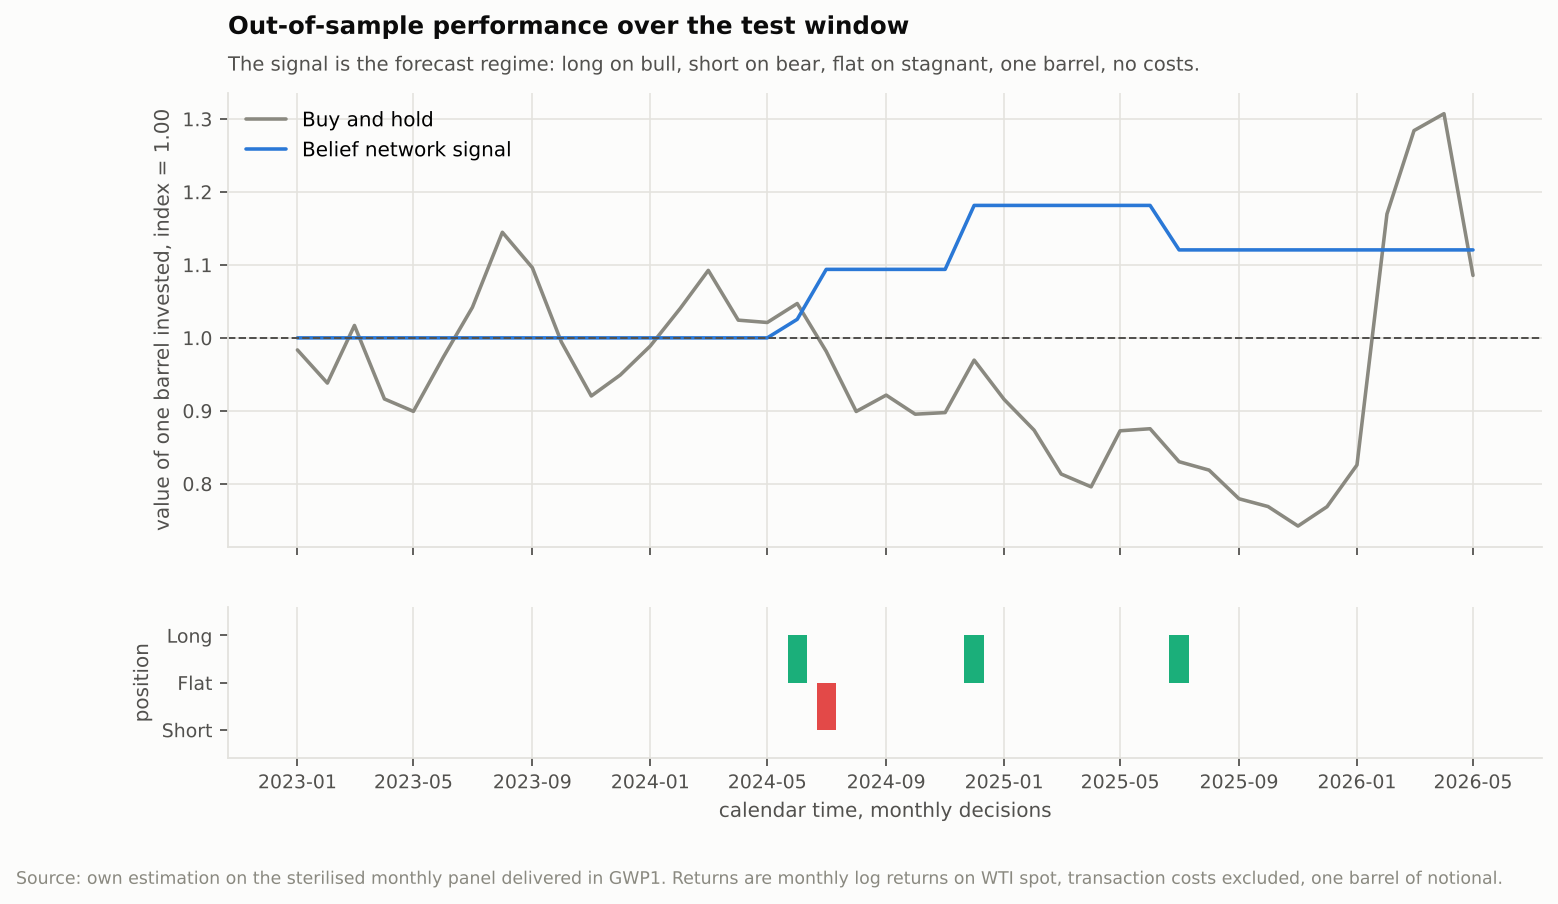

In [11]:
display(pd.DataFrame([res["backtest"]["model"], res["backtest"]["buy_and_hold"]]))
display(Image("figures/G14_backtest.png"))

**Answer.** Over the 41 scored months the signal ends ahead, 12.1 per cent against
8.6 per cent, at a fifth of the volatility and a seventh of the drawdown, with return over
volatility of 0.53 against 0.08.

The reading has to be careful. The model holds a position in four months out of
forty-one; the other thirty-seven it is flat, because the dead band has made stagnant the
dominant regime. What the backtest measures is mostly the value of not being in the oil
market during a period when oil fell by a quarter and recovered. That is a risk control
result rather than a forecasting result, and four positioned months are too few to support
a claim about skill.

## **7. The figure audit**

The feedback on GWP1 asked for complete labels, axes and scales on every chart. The check
is written into the code rather than asserted: each figure records, at the moment it is
saved, whether its data axes carry labels and ticks and whether the figure carries a
source note.

In [12]:
pd.DataFrame(res["figure_audit"])

,figure,kind,data_axes,x_label,y_label,ticks_both_axes,source_note
0,G8_data_allocation.png,chart,1,True,True,True,True
1,G9_replication.png,chart,1,True,True,True,True
2,G10_indegree.png,chart,2,True,True,True,True
3,G11_score_selection.png,chart,1,True,True,True,True
4,G12_dead_band.png,chart,2,True,True,True,True
5,G13_episode_duration.png,chart,1,True,True,True,True
6,G14_backtest.png,chart,2,True,True,True,True
7,G15_final_network.png,diagram,0,n/a,n/a,n/a,True


## **8. Conclusion**

The dissertation's specification reproduces in magnitude and not in detail. Under causal
decoding neither the structure score nor the in-degree cap moves the forecast, because the
Markov blanket of the target collapses onto the current price. The improvement recommended
by GWP2 works, and measuring it correctly cuts the apparent gain from forty-five
percentage points to five while restoring all three regimes and six variables to the
model.

**References**

- Alvi, Danish A. *Application of Probabilistic Graphical Models in Forecasting Crude Oil
  Price.* 2018. University College London, dissertation. arXiv,
  https://arxiv.org/abs/1804.10869.
- Ankan, Ankur, and Abinash Panda. "pgmpy: Probabilistic Graphical Models using Python."
  *Proceedings of the 14th Python in Science Conference*, 2015.
- Lopatovsky, Lukas. *hmms: Discrete and Continuous-Time Hidden Markov Model Library.*
  2017, https://github.com/lopatovsky/HMMs.


---
Copyright 2026 Group 18580, MScFE 660 Risk Management, WorldQuant University. Prepared for
assessment.